# Middle East airport passengers, 2025

Recomputes the headline figures from the tidy table and checks them against the build script output (`data/processed/headline_figures.csv`). Run from the `notebooks/` folder after `python scripts/build_data.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

tidy = pd.read_csv('../data/processed/passengers_tidy.csv')
headline = pd.read_csv('../data/processed/headline_figures.csv', index_col='measure')['value']
print(tidy.shape)
print(tidy.isna().sum().to_dict())
print('duplicates:', tidy.duplicated(['airport_code', 'year']).sum())
print(tidy.groupby('year')['airport_code'].count().to_dict())

(31, 9)
{'airport_code': 0, 'airport': 0, 'city': 0, 'country': 0, 'subregion': 0, 'year': 0, 'passengers': 0, 'check': 0, 'chosen_source': 0}
duplicates: 0
{2019: 6, 2024: 12, 2025: 13}


## Data checks

One row per airport and year. Passenger counts must be positive and below 110 million (Atlanta, the world's busiest airport, handled 106.3 million in 2025).

In [2]:
assert tidy['passengers'].between(1, 110_000_000).all()
assert not tidy.duplicated(['airport_code', 'year']).any()
tidy.groupby('check')['airport_code'].count()

check
derived           2
one-document      5
two-documents    24
Name: airport_code, dtype: int64

## 2025 ranking and change on 2024

In [3]:
wide = tidy.pivot(index='airport_code', columns='year', values='passengers')
wide['change_vs_2024_pct'] = ((wide[2025] / wide[2024] - 1) * 100).round(1)
wide['change_vs_2019_pct'] = ((wide[2025] / wide[2019] - 1) * 100).round(1)
wide = wide.sort_values(2025, ascending=False)
wide

year,2019,2024,2025,change_vs_2024_pct,change_vs_2019_pct
airport_code,,,,,
DXB,86396757.0,92300000.0,95192160.0,3.1,10.2
IST,NaN,80400000.0,84437710.0,5.0,NaN
DOH,38786422.0,52700000.0,54300000.0,3.0,40.0
JED,NaN,49120000.0,53400000.0,8.7,NaN
SAW,35470000.0,41400000.0,48420757.0,17.0,36.5
RUH,NaN,37200000.0,40800000.0,9.7,NaN
CAI,NaN,28974544.0,30944269.0,6.8,NaN
SHJ,13600000.0,17101725.0,19480000.0,13.9,43.2
TLV,NaN,13900000.0,18500000.0,33.1,NaN


In [4]:
WORLD = 3.6  # ACI World, preliminary 2025, total passengers on 2024
both = wide.dropna(subset=[2024])
above = int((both['change_vs_2024_pct'] > WORLD).sum())
print(f'{above} of {len(both)} airports grew faster than the world')
assert above == int(headline['airports_above_world_growth'])
assert len(both) == int(headline['airports_with_2024'])
assert int(wide.loc['DXB', 2025]) == int(headline['dxb_2025'])
assert wide.loc['DOH', 'change_vs_2019_pct'] == float(headline['doh_change_vs_2019_pct'])
assert wide.loc['SHJ', 'change_vs_2019_pct'] == float(headline['shj_change_vs_2019_pct'])
assert wide.loc['DXB', 'change_vs_2019_pct'] == float(headline['dxb_change_vs_2019_pct'])
print('headline figures match the build script')

9 of 12 airports grew faster than the world
headline figures match the build script


## Subregion totals (airports with both years)

In [5]:
meta = tidy.drop_duplicates('airport_code').set_index('airport_code')['subregion']
b = both.join(meta)
g = b.groupby('subregion')[[2024, 2025]].sum()
g['change_pct'] = ((g[2025] / g[2024] - 1) * 100).round(1)
print(g)
assert g.loc['Gulf', 'change_pct'] == float(headline['gulf_change_vs_2024_pct'])
total = round((b[2025].sum() / b[2024].sum() - 1) * 100, 1)
print('all 12 airports:', total)
assert total == float(headline['all_covered_change_vs_2024_pct'])

                     2024         2025  change_pct
subregion                                         
Gulf          270632258.0  286069719.0         5.7
Levant         22698595.0   28289851.0        24.6
North Africa   28974544.0   30944269.0         6.8
Turkey        121800000.0  132858467.0         9.1
all 12 airports: 7.7


## Chart

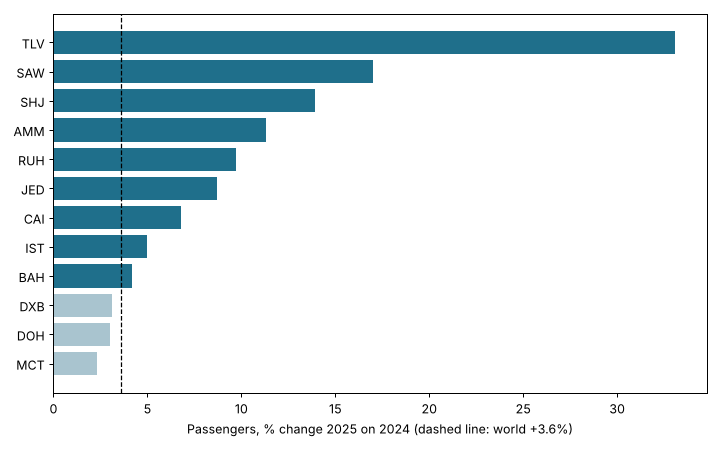

In [6]:
s = wide.dropna(subset=['change_vs_2024_pct']).sort_values('change_vs_2024_pct')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(s.index, s['change_vs_2024_pct'], color=['#1f6f8b' if v > WORLD else '#a9c4cf' for v in s['change_vs_2024_pct']])
ax.axvline(WORLD, color='black', ls='--', lw=1)
ax.set_xlabel('Passengers, % change 2025 on 2024 (dashed line: world +3.6%)')
plt.tight_layout()
plt.show()

## World context (ACI World preliminary 2025)

Middle East airports first, then the other regions.

In [7]:
world = pd.read_csv('../data/processed/world_top10_2025.csv')
world['me_first'] = (world['region'] != 'Middle East').astype(int)
world.sort_values(['ranking', 'me_first', 'rank_2025'])[['ranking', 'rank_2025', 'airport_code', 'region', 'passengers_2025', 'pct_change_vs_2024']]

,ranking,rank_2025,airport_code,region,passengers_2025,pct_change_vs_2024
10,international,1,DXB,Middle East,95192160,NaN
15,international,6,IST,Middle East,66608849,NaN
19,international,10,DOH,Middle East,54338667,NaN
11,international,2,LHR,Europe,79874784,NaN
12,international,3,ICN,Asia-Pacific,73554772,NaN
13,international,4,SIN,Asia-Pacific,69402000,NaN
14,international,5,AMS,Europe,68767548,NaN
16,international,7,CDG,Europe,66135938,NaN
17,international,8,HKG,Asia-Pacific,60824359,NaN
18,international,9,FRA,Europe,57528528,NaN
